In [1]:
from pathlib import Path

import numpy as np
import jax
import jax.numpy as jnp
import jax.scipy as jsp
import scipy
import matplotlib.pyplot as plt
import operator
from jax import config
from functools import partial
from matplotlib.lines import Line2D
config.update("jax_enable_x64", True)

import os

import polars as pl
import statistics

In [2]:
RESULTS_DIR = Path("..") / "data" / "results" / "toy_example"

In [3]:
true_flux = np.load(RESULTS_DIR / "true_flux.npy")
true_flux

array([100., 110.,  50.,  20.,  20.,  80.])

In [4]:
true_composition = np.load(RESULTS_DIR / "true_composition.npy")
true_composition

array([6.34920635e-05, 8.00761905e-01, 1.98285714e-01, 8.88888889e-04])

In [5]:
intensity_measurements = np.load(RESULTS_DIR / "intensity_measurements.npy")
intensity_measurements.shape

(1000, 4)

In [6]:
estimated_fluxes_euclidean = np.load(RESULTS_DIR / "estimated_fluxes_euclidean.npy")
estimated_fluxes_euclidean.shape

(1000, 6)

In [7]:
estimated_fluxes_clr = np.load(RESULTS_DIR / "estimated_fluxes_clr.npy")
estimated_fluxes_clr.shape

(1000, 6)

In [8]:
np.quantile(estimated_fluxes_euclidean, q=[0.05, 0.95], axis=0).T

array([[100.        , 100.        ],
       [ 89.45130635, 139.57592038],
       [ 34.63687768,  75.53444574],
       [ 17.43954322,  22.84662808],
       [ 17.43954322,  22.84662808],
       [ 77.15337192,  82.56045678]])

In [9]:
np.quantile(estimated_fluxes_clr, q=[0.05, 0.95], axis=0).T

array([[100.        , 100.        ],
       [ 90.69541158, 135.836714  ],
       [ 36.41166058,  71.75043656],
       [ 17.47111638,  22.86685267],
       [ 17.47111638,  22.86685267],
       [ 77.13314733,  82.52888362]])

In [10]:
estimated_fluxes_euclidean[214]

array([100.        , 210.962998  , 137.61829413,  13.32764806,
        13.32764806,  86.67235194])

In [11]:
true_flux

array([100., 110.,  50.,  20.,  20.,  80.])

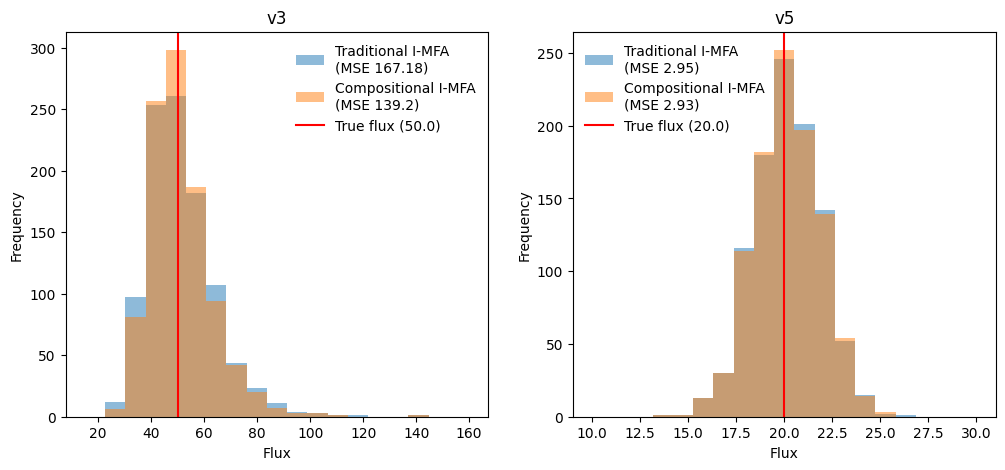

In [12]:
f, axes = plt.subplots(1, 2, figsize=[12, 5])

resid_euclidean = (estimated_fluxes_euclidean - true_flux)[:, [2, 4]] # index of free fluxes
resid_clr = (estimated_fluxes_clr - true_flux)[:, [2, 4]] # index of free fluxes

mse_euclidean = (resid_euclidean ** 2).mean(axis=0)
mse_clr = (resid_clr ** 2).mean(axis=0)


for (i, ax), xmin, xmax, flux_ix in zip(enumerate(axes), (15, 10), (160, 30), [2, 4]):
    bins = np.linspace(xmin, xmax, 20)
    h_euclidean = ax.hist(
        estimated_fluxes_euclidean[:, flux_ix], 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE {mse_euclidean[i].round(2)})" 
    )
    h_clr = ax.hist(
        estimated_fluxes_clr[:, flux_ix], 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE {mse_clr[i].round(2)})" 
    )
    ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"v{flux_ix+1}", xlabel="Flux", ylabel="Frequency")
    ax.legend(frameon=False)

**Figure caption** Traditional vs Compositional I-MFA estimates on a toy model. We fit traditional and compositional I-MFA to 1000 simulated datasets based on the toy model in [Antoniewicz reference]. The datasets were simulated assuming noise on pre-closure measurements with constant coefficient of variation based on a model of mass spectrometer intensity measurements (lognormal scale parameter 0.1, corresponding to approximately 2% worst error after closure to compositions).

In [13]:
# Making simulated data. 
total_mol = 1e5
total_isos = total_mol*data
rng = np.random.default_rng(seed=1234)

sims = 1000
# norm_sigma = total_mol*0.0002
# norm_sigma = total_isos*0.015
norm_sigma = np.array([total_isos[0]*0.3, total_isos[1]*0.05, total_isos[2]*0.05, total_isos[3]*0.3])
norm_sim = np.array(total_isos + rng.normal(0, norm_sigma, size=(sims,4)))
# np.clip(norm_sim, 1e-12, None, out=norm_sim)

# lognorm_sim = np.exp(np.log(total_isos) + rng.normal(0, 0.07, size=(sims, 4)))
df = pl.from_numpy(norm_sim, schema=["m0", "m1", "m2", "m3"])
df.insert_column(column=(pl.col("m0")/(pl.col("m0")+pl.col("m1")+pl.col("m2")+pl.col("m3"))).alias("m0_com"), index=4)
df.insert_column(column=(pl.col("m1")/(pl.col("m0")+pl.col("m1")+pl.col("m2")+pl.col("m3"))).alias("m1_com"), index=5)
df.insert_column(column=(pl.col("m2")/(pl.col("m0")+pl.col("m1")+pl.col("m2")+pl.col("m3"))).alias("m2_com"), index=6)
df.insert_column(column=(pl.col("m3")/(pl.col("m0")+pl.col("m1")+pl.col("m2")+pl.col("m3"))).alias("m3_com"), index=7)

NameError: name 'data' is not defined

In [ ]:
D_sim_vec = jnp.array([statistics.stdev(df["m0_com"]), statistics.stdev(df["m1_com"]), statistics.stdev(df["m2_com"]), statistics.stdev(df["m3_com"])])
D_sim_vec

In [ ]:
f123_sim = jnp.array([statistics.mean(df["m0_com"]), statistics.mean(df["m1_com"]), statistics.mean(df["m2_com"]), statistics.mean(df["m3_com"])])
D_sim = jnp.diag(D_sim_vec)

In [ ]:
colors =["#73102A", "#038C7F", "#558C03", "#F2CB05", "#D9A404", "#1C0B9C"]

fig, ((ax1, ax2),(ax3,ax4)) = plt.subplots(nrows=2, ncols=2, figsize=(8,8), layout="constrained")
ax1.hist(df["m0"].to_numpy(), bins=15, density=True, label="Simulated m+0", color=colors[1])
ax2.hist(df["m1"].to_numpy(), bins=15, density=True, label="Simulated m+1", color=colors[2])
ax3.hist(df["m2"].to_numpy(), bins=15, density=True, label="Simulated m+2", color=colors[4])
ax4.hist(df["m3"].to_numpy(), bins=15, density=True, label="Simulated m+3", color=colors[0])

ax1.axvline(total_isos[0], color=colors[5], label="True")
ax2.axvline(total_isos[1], color=colors[5], label="True")
ax3.axvline(total_isos[2], color=colors[5], label="True")
ax4.axvline(total_isos[3], color=colors[5], label="True")

total_mean = jnp.array([statistics.mean(df["m0"]), statistics.mean(df["m1"]), statistics.mean(df["m2"]), statistics.mean(df["m3"])])

ax1.axvline(total_mean[0], color="red", linestyle="dashed", label="Mean")
ax2.axvline(total_mean[1], color="red", linestyle="dashed", label="Mean")
ax3.axvline(total_mean[2], color="red", linestyle="dashed", label="Mean")
ax4.axvline(total_mean[3], color="red", linestyle="dashed", label="Mean")


ax1.set_title("m+0", size=20)
ax2.set_title("m+1", size=20)
ax3.set_title("m+2", size=20)
ax4.set_title("m+3", size=20)

ax1.set_xlabel("Reads", size=12)
ax2.set_xlabel("Reads", size=12)
ax3.set_xlabel("Reads", size=12)
ax4.set_xlabel("Reads", size=12)

ax1.set_ylabel("Density", size=12)
ax2.set_ylabel("Density", size=12)
ax3.set_ylabel("Density", size=12)
ax4.set_ylabel("Density", size=12)

ax1.ticklabel_format(scilimits=(-2,2))
ax2.ticklabel_format(scilimits=(-2,2))
ax3.ticklabel_format(scilimits=(-2,2))
ax4.ticklabel_format(scilimits=(-2,2))

# Custom legend
custom_marker = [
    Line2D([0], [0], color="gray", marker="s", linestyle="", markersize=8),
    Line2D([0], [0], color=colors[5], marker="", linestyle="-", markersize=8),
    Line2D([0], [0], color="red", marker="", linestyle="dashed", markersize=8)
]
fig.legend(custom_marker, ["Simulated reads", "True read", "Mean(simulated reads)"], fontsize=14, loc="outside upper right")

fig.suptitle("Simulated data of F123", size=20, x=0.05, y=0.96, ha="left")

plt.show()

In [ ]:
fig, ((ax1, ax2),(ax3,ax4)) = plt.subplots(nrows=2, ncols=2, figsize=(8,8), layout="constrained")
ax1.hist(df["m0_com"].to_numpy(), bins=15, density=True, label="Simulated m0", color=colors[1])
ax2.hist(df["m1_com"].to_numpy(), bins=15, density=True, label="Simulated m1", color=colors[2])
ax3.hist(df["m2_com"].to_numpy(), bins=15, density=True, label="Simulated m2", color=colors[4])
ax4.hist(df["m3_com"].to_numpy(), bins=15, density=True, label="Simulated m3", color=colors[0])

ax1.axvline(data[0], color=colors[5], label="True")
ax2.axvline(data[1], color=colors[5], label="True")
ax3.axvline(data[2], color=colors[5], label="True")
ax4.axvline(data[3], color=colors[5], label="True")

ax1.axvline(f123_sim[0], color="red", linestyle="dashed", label="Mean")
ax2.axvline(f123_sim[1], color="red", linestyle="dashed", label="Mean")
ax3.axvline(f123_sim[2], color="red", linestyle="dashed", label="Mean")
ax4.axvline(f123_sim[3], color="red", linestyle="dashed", label="Mean")

ax1.set_title("m+0", size=20)
ax2.set_title("m+1", size=20)
ax3.set_title("m+2", size=20)
ax4.set_title("m+3", size=20)

ax1.set_xlabel("Fraction", size=12)
ax2.set_xlabel("Fraction", size=12)
ax3.set_xlabel("Fraction", size=12)
ax4.set_xlabel("Fraction", size=12)

ax1.set_ylabel("Density", size=12)
ax2.set_ylabel("Density", size=12)
ax3.set_ylabel("Density", size=12)
ax4.set_ylabel("Density", size=12)

ax1.ticklabel_format(scilimits=(-2,2))
ax2.ticklabel_format(scilimits=(-2,2))
ax3.ticklabel_format(scilimits=(-2,2))
ax4.ticklabel_format(scilimits=(-2,2))

# Custom legend
custom_marker = [
    Line2D([0], [0], color="gray", marker="s", linestyle="", markersize=8),
    Line2D([0], [0], color=colors[5], marker="", linestyle="-", markersize=8),
    Line2D([0], [0], color="red", marker="", linestyle="dashed", markersize=8)
]
fig.legend(custom_marker, ["Simulated fraction", "True fraction", "Mean(simulated fraction)"], fontsize=14, loc="outside upper right")

fig.suptitle("Simulated fractions of F123", size=20, x=0.05, y=0.95, ha = "left")

# plt.legend(loc="upper right")

plt.show()

## CLR transformed simulations

In [ ]:
rng = np.random.default_rng(seed=1234)
clr_data = clr(data)
sims = 1000
norm_clr = np.array(clr_data+ rng.normal(0, 0.001, size=(sims,4)))


In [ ]:
clr_arr = clr(pl.DataFrame(data= {"m0": df["m0_com"], "m1": df["m1_com"], "m2": df["m2_com"], "m3": df["m3_com"]}))
clr_m0 = np.array([clr_arr[i][0] for i in range(len(clr_arr))])
clr_m1 = np.array([clr_arr[i][1] for i in range(len(clr_arr))])
clr_m2 = np.array([clr_arr[i][2] for i in range(len(clr_arr))])
clr_m3 = np.array([clr_arr[i][3] for i in range(len(clr_arr))])

df_clr = pl.DataFrame(
    data={
        "m0": df["m0_com"], 
        "m1": df["m1_com"],
        "m2": df["m2_com"],
        "m3": df["m3_com"],
        "m0_clr": clr_m0,
        "m1_clr": clr_m1,
        "m2_clr": clr_m2,
        "m3_clr": clr_m3,
    }
)
df_clr

In [ ]:
f123_sim_clr = jnp.array([statistics.mean(df_clr["m0_clr"]), statistics.mean(df_clr["m1_clr"]), statistics.mean(df_clr["m2_clr"]), statistics.mean(df_clr["m3_clr"])])

D_sim_clr = jnp.diag(jnp.array([statistics.stdev(df_clr["m0_clr"]), statistics.stdev(df_clr["m1_clr"]), statistics.stdev(df_clr["m2_clr"]), statistics.stdev(df_clr["m3_clr"])]))

In [ ]:
fig_clr, ((ax1_clr, ax2_clr),(ax3_clr,ax4_clr)) = plt.subplots(nrows=2, ncols=2, figsize=(8,8), layout="constrained")
ax1_clr.hist(df_clr["m0_clr"].to_numpy(), bins=15, density=True, label="Simulated m0", color=colors[1])
ax2_clr.hist(df_clr["m1_clr"].to_numpy(), bins=15, density=True, label="Simulated m1", color=colors[2])
ax3_clr.hist(df_clr["m2_clr"].to_numpy(), bins=15, density=True, label="Simulated m2", color=colors[4])
ax4_clr.hist(df_clr["m3_clr"].to_numpy(), bins=15, density=True, label="Simulated m3", color=colors[0])

data_clr=clr_func(data)
ax1_clr.axvline(data_clr[0], color=colors[5], label="True")
ax2_clr.axvline(data_clr[1], color=colors[5], label="True")
ax3_clr.axvline(data_clr[2], color=colors[5], label="True")
ax4_clr.axvline(data_clr[3], color=colors[5], label="True")

ax1_clr.axvline(f123_sim_clr[0], color="red", linestyle="dashed", label="Mean")
ax2_clr.axvline(f123_sim_clr[1], color="red", linestyle="dashed", label="Mean")
ax3_clr.axvline(f123_sim_clr[2], color="red", linestyle="dashed", label="Mean")
ax4_clr.axvline(f123_sim_clr[3], color="red", linestyle="dashed", label="Mean")

ax1_clr.set_title("m+0", size=20)
ax2_clr.set_title("m+1", size=20)
ax3_clr.set_title("m+2", size=20)
ax4_clr.set_title("m+3", size=20)

ax1_clr.set_xlabel("CLR(fraction)", size=12)
ax2_clr.set_xlabel("CLR(fraction)", size=12)
ax3_clr.set_xlabel("CLR(fraction)", size=12)
ax4_clr.set_xlabel("CLR(fraction)", size=12)

ax1_clr.set_ylabel("Density", size=12)
ax2_clr.set_ylabel("Density", size=12)
ax3_clr.set_ylabel("Density", size=12)
ax4_clr.set_ylabel("Density", size=12)

# Custom legend
custom_marker = [
    Line2D([0], [0], color="gray", marker="s", linestyle="", markersize=8),
    Line2D([0], [0], color=colors[5], marker="", linestyle="-", markersize=8),
    Line2D([0], [0], color="red", marker="", linestyle="dashed", markersize=8)
]
fig_clr.legend(custom_marker, ["CLR(Simulated fraction)", "CLR(True fraction)", "Mean(CLR(simulated fraction))"], fontsize=14, loc="outside upper right")

fig_clr.suptitle("CLR transformed fractions", size=20, x=0.05, y=0.95, ha = "left") 

plt.show()